# 05 — Full Hyperparameter Tuning and Comparative Evaluation of the Six Classifiers

## Objective
This notebook completes grading criteria **1.4 (Optimisation & Cross-Validation)** and **1.5 (Comparative Metrics)** of the project specification:

- `GridSearchCV` with group-aware **5-fold** cross-validation is applied to **every tunable model** (Zero-R included for completeness), not only to the best one.
- The SVM study covers the three kernels required by the course: **linear, RBF and polynomial**.
- KNN: study of **k** and of the **distance metric** (Manhattan vs Euclidean). Decision Tree: **Gini vs entropy** and **pruning** (`max_depth`, `min_samples_leaf`, `ccp_alpha`).
- All tuned models are evaluated **once** on the held-out test set with a multi-criteria table, **six confusion matrices**, **ROC curves (one-vs-rest)**, a **precision–recall curve** for the rare class, and a **statistical comparison** of the models.

## Protocol (identical to Notebook 03)
- Data: `data/processed/train.csv` (model selection) and `data/processed/test.csv` (final evaluation only).
- Preprocessing: the project pipeline `src/preprocessing.make_preprocessor("full")`, fitted inside each fold (no leakage).
- Cross-validation: `StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)`; groups = hash of the 11 features, so identical flows never sit on both sides of a split.
- Selection metric: **macro-F1** over the four actions (the rare class `reset-both` weighs as much as `allow`).

In [1]:
from pathlib import Path
import sys, os, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if not (ROOT / "src" / "preprocessing.py").exists():
    raise FileNotFoundError("Run this notebook from the repository root or from notebooks/.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import (f1_score, accuracy_score, balanced_accuracy_score, precision_recall_fscore_support,
                             roc_auc_score, roc_curve, average_precision_score, precision_recall_curve,
                             confusion_matrix, ConfusionMatrixDisplay)
from sklearn.preprocessing import label_binarize
from scipy.stats import friedmanchisquare, binomtest

from src.preprocessing import make_preprocessor, get_feature_columns
from src.models import build_model

RANDOM_STATE = 42
CLASS_LABELS = ["allow", "deny", "drop", "reset-both"]
QUICK = os.environ.get("FDD_QUICK", "0") == "1"   # leave at 0 for the real run

REPORTS = ROOT / "reports" / "tuning"
FIGURES = ROOT / "docs" / "latex" / "figures" / "ch05"
REPORTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
warnings.filterwarnings("ignore", category=FutureWarning)
print("Python", sys.version.split()[0], "| quick mode:", QUICK)

Python 3.14.4 | quick mode: False


In [2]:
train_df = pd.read_csv(ROOT / "data" / "processed" / "train.csv")
test_df = pd.read_csv(ROOT / "data" / "processed" / "test.csv")
FEATURES = get_feature_columns("full")

if QUICK:  # small stratified subsample, only to check that the notebook runs end to end
    train_df = pd.concat([g.sample(min(len(g), 1500), random_state=RANDOM_STATE)
                          for _, g in train_df.groupby("Action")])

X_train, y_train = train_df[FEATURES], train_df["Action"].str.strip().str.lower()
X_test, y_test = test_df[FEATURES], test_df["Action"].str.strip().str.lower()
groups = pd.util.hash_pandas_object(X_train, index=False).to_numpy()
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def macro_f1(estimator, X, y):
    return f1_score(y, estimator.predict(X), labels=CLASS_LABELS, average="macro", zero_division=0)

for k, (tr, va) in enumerate(cv.split(X_train, y_train, groups), 1):
    assert set(groups[tr]).isdisjoint(groups[va])          # no identical flow on both sides
print(f"train {X_train.shape}, test {X_test.shape}")
display(pd.concat([y_train.value_counts(), y_test.value_counts()], axis=1, keys=["train", "test"]))

train (45736, 11), test (11434, 11)


,train,test
Action,,
allow,29951,7488
drop,9308,2327
deny,6434,1608
reset-both,43,11


## 1. Search spaces

| Model | Hyperparameters explored | Why |
|---|---|---|
| Zero-R | strategy | Baseline (exempt from tuning, searched for completeness). |
| KNN | k ∈ {5, 11, 21, 31, 41, 51}, weights ∈ {uniform, distance}, p ∈ {1 (Manhattan), 2 (Euclidean)} | Bias–variance trade-off of k; effect of the distance metric on standardised features. k = 21 was on the edge of the previous grid, so the grid is extended. |
| Decision Tree | criterion ∈ {gini, entropy}, max_depth ∈ {10, 20, 30, None}, min_samples_leaf ∈ {1, 5}, ccp_alpha ∈ {0, 1e-4}, class_weight ∈ {None, balanced} | Impurity measure and pre-/post-pruning against overfitting; class weighting for `reset-both`. |
| Random Forest | n_estimators = 200, max_features ∈ {sqrt, 0.5}, min_samples_leaf ∈ {1, 2}, class_weight ∈ {None, balanced_subsample} | Decorrelation of trees (max_features), leaf size, class weighting. |
| Gaussian NB | var_smoothing ∈ 10^-11 … 10^-5 | Variance smoothing: the Gaussian analogue of Laplace smoothing. |
| SVM (SVC) | linear: C; RBF: C, γ; polynomial: C, degree | Kernel study required by the course. |

**SVM cost note.** Kernel SVC scales roughly quadratically with the number of rows, so the SVM search uses a stratified sample of the training set (≤ 4,000 rows per class, **all** `reset-both` rows), with the same grouped folds. The selected SVM is then refitted on this sample. This choice is stated in the report.

In [3]:
GRIDS = {
    "Dummy (Zero-R)": {"classifier__strategy": ["most_frequent", "prior", "stratified"]},
    "KNN": {"classifier__n_neighbors": [5, 11, 21, 31, 41, 51],
            "classifier__weights": ["uniform", "distance"],
            "classifier__p": [1, 2]},
    "Decision Tree": {"classifier__criterion": ["gini", "entropy"],
                      "classifier__max_depth": [10, 20, 30, None],
                      "classifier__min_samples_leaf": [1, 5],
                      "classifier__ccp_alpha": [0.0, 1e-4],
                      "classifier__class_weight": [None, "balanced"]},
    "Random Forest": {"classifier__n_estimators": [200],
                      "classifier__max_features": ["sqrt", 0.5],
                      "classifier__min_samples_leaf": [1, 2],
                      "classifier__class_weight": [None, "balanced_subsample"]},
    "Gaussian Naive Bayes": {"classifier__var_smoothing": list(np.logspace(-11, -5, 7))},
    "SVM (SVC)": [{"classifier__kernel": ["linear"], "classifier__C": [0.1, 1, 10]},
                  {"classifier__kernel": ["rbf"], "classifier__C": [1, 10, 100],
                   "classifier__gamma": ["scale", 0.01, 0.1]},
                  {"classifier__kernel": ["poly"], "classifier__C": [1, 10], "classifier__degree": [2, 3]}],
}
if QUICK:
    GRIDS["KNN"] = {"classifier__n_neighbors": [5, 21], "classifier__weights": ["distance"], "classifier__p": [1, 2]}
    GRIDS["Decision Tree"] = {"classifier__criterion": ["gini", "entropy"], "classifier__max_depth": [10, None]}
    GRIDS["Random Forest"] = {"classifier__n_estimators": [50], "classifier__class_weight": [None, "balanced_subsample"]}

def make_estimator(name):
    if name == "SVM (SVC)":
        return Pipeline([("preprocessing", make_preprocessor("full")),
                         ("classifier", SVC(random_state=RANDOM_STATE, cache_size=1000))])
    return build_model(name, "full")

def svm_sample(X, y, g, per_class=4000):
    labels = pd.Series(y.to_numpy(), index=X.index)
    idx = pd.concat([d.sample(min(len(d), per_class), random_state=RANDOM_STATE)
                     for _, d in labels.groupby(labels)]).index
    pos = np.sort(X.index.get_indexer(idx))
    return X.iloc[pos], y.iloc[pos], g[pos]

from sklearn.model_selection import ParameterGrid
n_candidates = {m: len(ParameterGrid(g)) for m, g in GRIDS.items()}
print(n_candidates, "| total fits:", 5 * sum(n_candidates.values()))

{'Dummy (Zero-R)': 3, 'KNN': 24, 'Decision Tree': 64, 'Random Forest': 8, 'Gaussian Naive Bayes': 7, 'SVM (SVC)': 16} | total fits: 610


## 2. Grid search on every model (training set only)
Expect about 20–30 minutes on a laptop; KNN is the slowest model. Every `cv_results_` table is saved in `reports/tuning/`.

In [4]:
searches, summary = {}, []
for name, grid in GRIDS.items():
    Xs, ys, gs_ = svm_sample(X_train, y_train, groups) if name == "SVM (SVC)" else (X_train, y_train, groups)
    t0 = time.perf_counter()
    search = GridSearchCV(make_estimator(name), grid, scoring=macro_f1, cv=cv, n_jobs=-1,
                          refit=True, return_train_score=True, error_score="raise")
    search.fit(Xs, ys, groups=gs_)
    elapsed = time.perf_counter() - t0
    searches[name] = search
    res = pd.DataFrame(search.cv_results_)
    res.to_csv(REPORTS / f"gridsearch_{name.split(' (')[0].replace(' ', '_').lower()}.csv", index=False)
    b = search.best_index_
    folds = [res.loc[b, f"split{i}_test_score"] for i in range(5)]
    summary.append({"model": name, "n_candidates": len(res), "train_rows": len(Xs),
                    "best_params": {k.replace("classifier__", ""): v for k, v in search.best_params_.items()},
                    "cv_macro_f1_mean": res.loc[b, "mean_test_score"], "cv_macro_f1_std": res.loc[b, "std_test_score"],
                    "cv_train_macro_f1": res.loc[b, "mean_train_score"], "fold_scores": folds,
                    "search_seconds": round(elapsed, 1)})
    print(f"{name:22s} best CV macro-F1 = {search.best_score_:.4f}  {search.best_params_}  ({elapsed:.0f} s)")

summary_df = pd.DataFrame(summary).sort_values("cv_macro_f1_mean", ascending=False)
summary_df.drop(columns="fold_scores").to_csv(REPORTS / "tuning_summary.csv", index=False)
display(summary_df.drop(columns="fold_scores"))

Dummy (Zero-R)         best CV macro-F1 = 0.2505  {'classifier__strategy': 'stratified'}  (13 s)


KNN                    best CV macro-F1 = 0.8478  {'classifier__n_neighbors': 5, 'classifier__p': 1, 'classifier__weights': 'distance'}  (796 s)
Decision Tree          best CV macro-F1 = 0.8478  {'classifier__ccp_alpha': 0.0, 'classifier__class_weight': None, 'classifier__criterion': 'gini', 'classifier__max_depth': 20, 'classifier__min_samples_leaf': 1}  (26 s)


Random Forest          best CV macro-F1 = 0.8479  {'classifier__class_weight': None, 'classifier__max_features': 0.5, 'classifier__min_samples_leaf': 2, 'classifier__n_estimators': 200}  (46 s)
Gaussian Naive Bayes   best CV macro-F1 = 0.7076  {'classifier__var_smoothing': np.float64(1e-05)}  (10 s)
SVM (SVC)              best CV macro-F1 = 0.8417  {'classifier__C': 10, 'classifier__gamma': 'scale', 'classifier__kernel': 'rbf'}  (6 s)


,model,n_candidates,train_rows,best_params,cv_macro_f1_mean,cv_macro_f1_std,cv_train_macro_f1,search_seconds
3,Random Forest,8,45736,"{'class_weight': None, 'max_features': 0.5, 'm...",0.847930,0.037791,0.849983,45.6
1,KNN,24,45736,"{'n_neighbors': 5, 'p': 1, 'weights': 'distance'}",0.847817,0.037818,0.850046,796.1
2,Decision Tree,64,45736,"{'ccp_alpha': 0.0, 'class_weight': None, 'crit...",0.847812,0.037855,0.850046,26.0
5,SVM (SVC),16,12043,"{'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}",0.841705,0.051595,0.849298,5.8
4,Gaussian Naive Bayes,7,45736,{'var_smoothing': 1e-05},0.707599,0.005569,0.709004,9.6
0,Dummy (Zero-R),3,45736,{'strategy': 'stratified'},0.250542,0.005457,0.252298,12.5


## 3. Validation curves (hyperparameter studies)
What the course asks to *study*: the effect of k and of the distance metric for KNN, of depth and impurity for the tree, and of C and γ for the RBF kernel. A good optimum lies **inside** the explored range, not on its edge.

Best CV macro-F1 per SVM kernel:
 param_classifier__kernel
linear    0.8357
poly      0.8360
rbf       0.8417


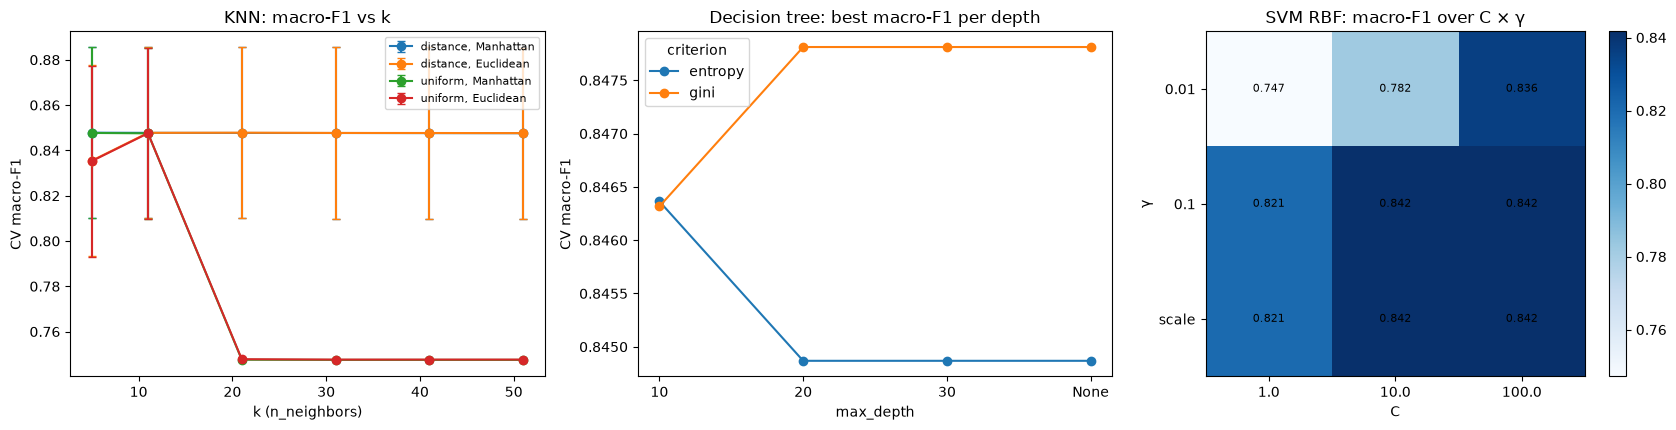

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))

r = pd.DataFrame(searches["KNN"].cv_results_)
for (w, p), d in r.groupby(["param_classifier__weights", "param_classifier__p"]):
    d = d.sort_values("param_classifier__n_neighbors")
    axes[0].errorbar(d["param_classifier__n_neighbors"], d["mean_test_score"], yerr=d["std_test_score"],
                     marker="o", capsize=3, label=f"{w}, {'Manhattan' if p == 1 else 'Euclidean'}")
axes[0].set(title="KNN: macro-F1 vs k", xlabel="k (n_neighbors)", ylabel="CV macro-F1"); axes[0].legend(fontsize=8)

r = pd.DataFrame(searches["Decision Tree"].cv_results_)
r["depth"] = r["param_classifier__max_depth"].astype(object).fillna("None").astype(str)
best = r.groupby(["param_classifier__criterion", "depth"])["mean_test_score"].max().unstack(0)
best = best.reindex([d for d in ["10", "20", "30", "None"] if d in best.index])
for crit in best.columns:
    axes[1].plot(range(len(best)), best[crit], marker="o", label=crit)
axes[1].set_xticks(range(len(best)), best.index); axes[1].legend(title="criterion")
axes[1].set(title="Decision tree: best macro-F1 per depth", xlabel="max_depth", ylabel="CV macro-F1")

r = pd.DataFrame(searches["SVM (SVC)"].cv_results_)
rbf = r[r["param_classifier__kernel"] == "rbf"]
if len(rbf):
    heat = rbf.pivot_table(index="param_classifier__gamma", columns="param_classifier__C",
                           values="mean_test_score", aggfunc="max")
    im = axes[2].imshow(heat.values, cmap="Blues", aspect="auto")
    axes[2].set_xticks(range(heat.shape[1]), heat.columns); axes[2].set_yticks(range(heat.shape[0]), heat.index)
    for i in range(heat.shape[0]):
        for j in range(heat.shape[1]):
            axes[2].text(j, i, f"{heat.values[i, j]:.3f}", ha="center", va="center", fontsize=8)
    axes[2].set(title="SVM RBF: macro-F1 over C × γ", xlabel="C", ylabel="γ"); fig.colorbar(im, ax=axes[2])
kern = r.groupby("param_classifier__kernel")["mean_test_score"].max()
print("Best CV macro-F1 per SVM kernel:\n", kern.round(4).to_string())
plt.tight_layout(); fig.savefig(FIGURES / "validation_curves.png", dpi=200, bbox_inches="tight"); plt.show()

## 4. One-time evaluation of all tuned models on the held-out test set

In [6]:
def scores_matrix(model, X):
    # Class scores aligned with CLASS_LABELS: probabilities when available, else SVM decision values.
    if hasattr(model, "predict_proba"):
        s, classes = model.predict_proba(X), list(model.classes_)
    else:
        s, classes = model.decision_function(X), list(model.classes_)
    return s[:, [classes.index(c) for c in CLASS_LABELS]]

Y_bin = label_binarize(y_test, classes=CLASS_LABELS)
rows, preds, scores = [], {}, {}
for name in summary_df["model"]:
    model = searches[name].best_estimator_
    y_pred = model.predict(X_test); S = scores_matrix(model, X_test)
    preds[name], scores[name] = y_pred, S
    p, r, f, _ = precision_recall_fscore_support(y_test, y_pred, labels=CLASS_LABELS, average="macro", zero_division=0)
    auc_per_class = [roc_auc_score(Y_bin[:, k], S[:, k]) for k in range(len(CLASS_LABELS))]
    t0 = time.perf_counter(); model.predict(X_test.iloc[:1000]); latency = (time.perf_counter() - t0)
    rows.append({"model": name,
                 "cv_macro_f1": summary_df.set_index("model").loc[name, "cv_macro_f1_mean"],
                 "test_accuracy": accuracy_score(y_test, y_pred),
                 "test_balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
                 "test_macro_precision": p, "test_macro_recall": r, "test_macro_f1": f,
                 "test_weighted_f1": f1_score(y_test, y_pred, labels=CLASS_LABELS, average="weighted", zero_division=0),
                 "test_roc_auc_ovr_macro": float(np.mean(auc_per_class)),
                 "test_pr_auc_reset_both": average_precision_score(Y_bin[:, 3], S[:, 3]),
                 "reset_both_recall": (y_pred[y_test.to_numpy() == "reset-both"] == "reset-both").mean(),
                 "ms_per_1000_rows": round(1000 * latency, 1)})

final_df = pd.DataFrame(rows).set_index("model").round(4)
final_df.to_csv(REPORTS / "final_model_comparison.csv")
display(final_df)

,cv_macro_f1,test_accuracy,test_balanced_accuracy,test_macro_precision,test_macro_recall,test_macro_f1,test_weighted_f1,test_roc_auc_ovr_macro,test_pr_auc_reset_both,reset_both_recall,ms_per_1000_rows
model,,,,,,,,,,,
Random Forest,0.8479,0.9985,0.7716,0.9977,0.7716,0.7900,0.9981,0.9976,0.1847,0.0909,692.0
KNN,0.8478,0.9984,0.7716,0.9975,0.7716,0.7899,0.9981,0.9309,0.1662,0.0909,242.5
Decision Tree,0.8478,0.9985,0.7716,0.9977,0.7716,0.7900,0.9981,0.9976,0.1848,0.0909,8.6
SVM (SVC),0.8417,0.9983,0.7715,0.9972,0.7715,0.7897,0.9979,0.9960,0.1389,0.0909,13.0
Gaussian Naive Bayes,0.7076,0.9502,0.9177,0.7535,0.9177,0.7101,0.9689,0.9926,0.0197,1.0000,7.4
Dummy (Zero-R),0.2505,0.4878,0.2498,0.2498,0.2498,0.2498,0.4892,0.4971,0.0010,0.0000,7.0


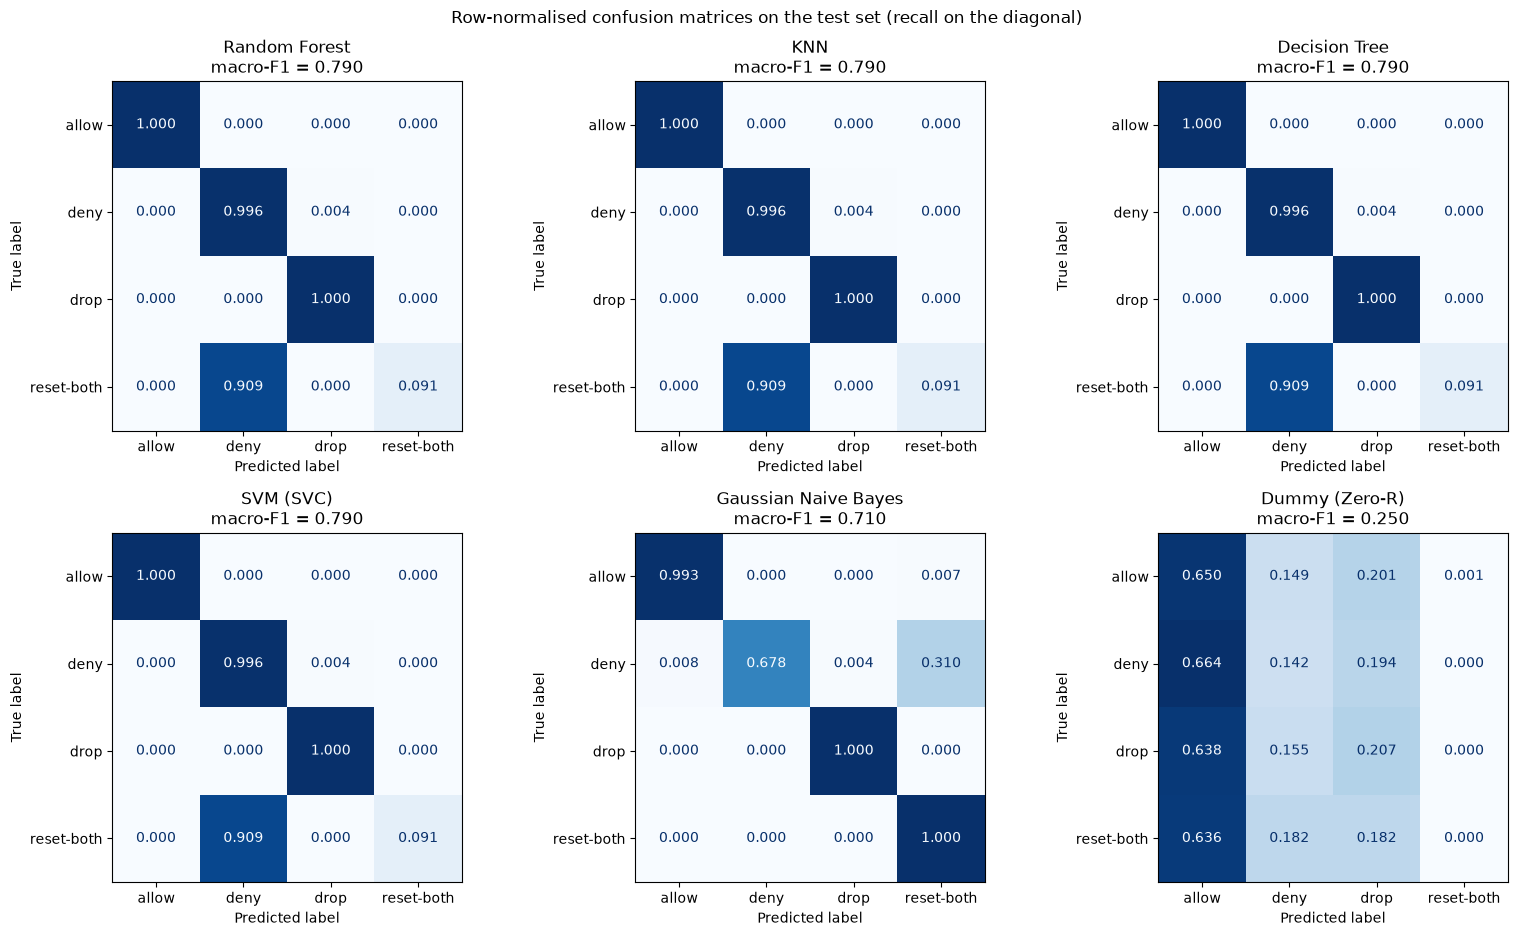

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9.5))
for ax, name in zip(axes.ravel(), summary_df["model"]):
    ConfusionMatrixDisplay.from_predictions(y_test, preds[name], labels=CLASS_LABELS, normalize="true",
                                            values_format=".3f", cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(f"{name}\nmacro-F1 = {final_df.loc[name, 'test_macro_f1']:.3f}")
plt.suptitle("Row-normalised confusion matrices on the test set (recall on the diagonal)")
plt.tight_layout(); fig.savefig(FIGURES / "confusion_matrices_6_models.png", dpi=200, bbox_inches="tight"); plt.show()

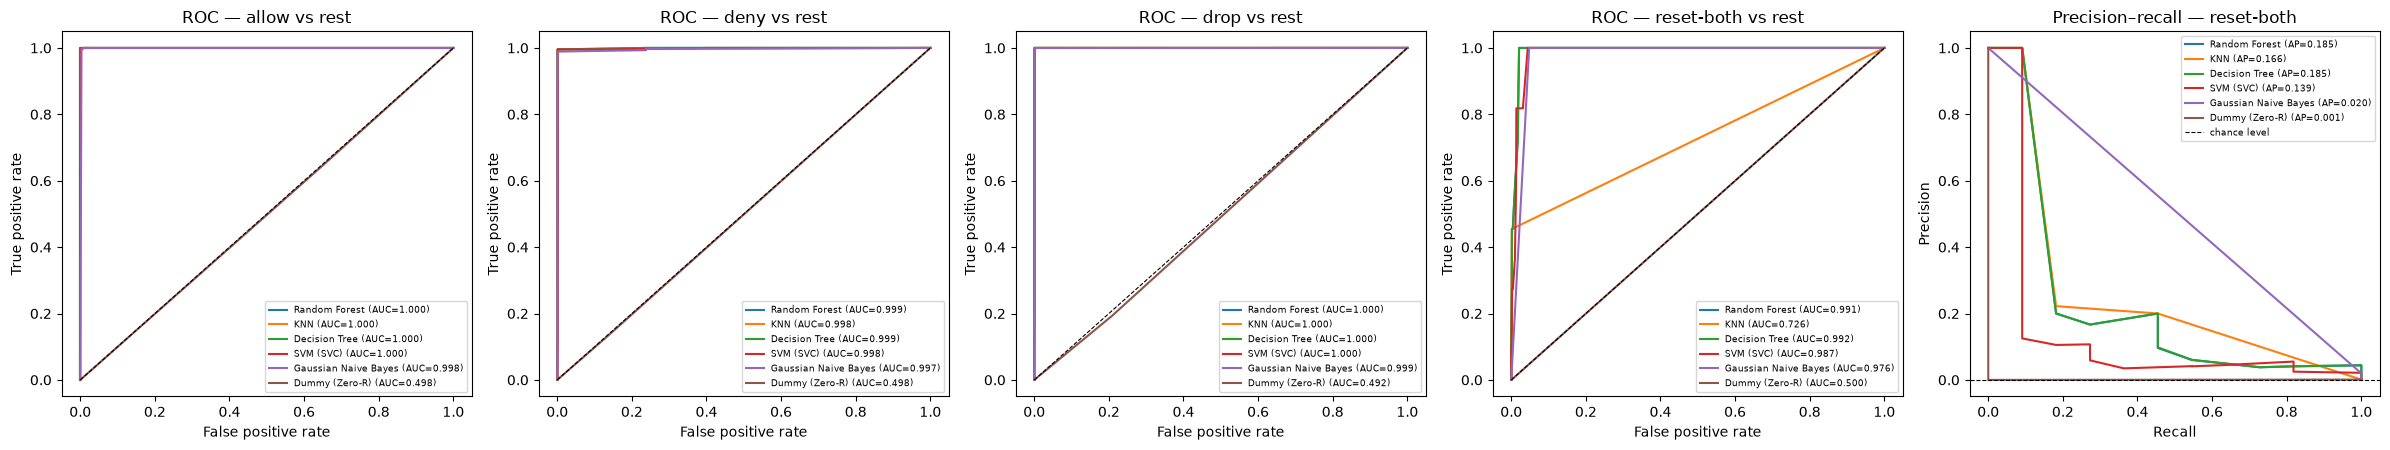

In [8]:
fig, axes = plt.subplots(1, 5, figsize=(24, 4.6))
for k, cls in enumerate(CLASS_LABELS):
    for name in summary_df["model"]:
        fpr, tpr, _ = roc_curve(Y_bin[:, k], scores[name][:, k])
        axes[k].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(Y_bin[:, k], scores[name][:, k]):.3f})")
    axes[k].plot([0, 1], [0, 1], "k--", lw=0.8)
    axes[k].set(title=f"ROC — {cls} vs rest", xlabel="False positive rate", ylabel="True positive rate")
    axes[k].legend(fontsize=6.5, loc="lower right")
for name in summary_df["model"]:
    prec, rec, _ = precision_recall_curve(Y_bin[:, 3], scores[name][:, 3])
    axes[4].plot(rec, prec, label=f"{name} (AP={final_df.loc[name, 'test_pr_auc_reset_both']:.3f})")
axes[4].axhline(Y_bin[:, 3].mean(), color="k", ls="--", lw=0.8, label="chance level")
axes[4].set(title="Precision–recall — reset-both", xlabel="Recall", ylabel="Precision"); axes[4].legend(fontsize=6.5)
plt.tight_layout(); fig.savefig(FIGURES / "roc_pr_curves.png", dpi=200, bbox_inches="tight"); plt.show()

## 5. Are the differences between models statistically significant?

- **Friedman test** on the five paired fold scores (same folds for every model): H0 = all models have the same macro-F1 distribution. Non-parametric, for k ≥ 3 related samples. SVM is excluded because it was tuned on a sample, so its folds are not paired with the others.
- **McNemar test** (exact binomial version) on the test set between the two best models: H0 = both models make the same proportion of errors on the same flows. It is the standard paired test for two classifiers evaluated on one test set.

With only 5 folds the Friedman test has little power; the McNemar test on 11,434 test flows is the more informative one.

In [9]:
paired = summary_df[summary_df["model"] != "SVM (SVC)"].set_index("model")["fold_scores"]
stat, p = friedmanchisquare(*paired.tolist())
print(f"Friedman, all {len(paired)} paired models: chi2 = {stat:.3f}, p = {p:.4g}  (expected: Zero-R and NB are clearly worse)")
top3 = paired.index[:3]          # summary_df is sorted by CV macro-F1
stat3, p3 = friedmanchisquare(*paired.loc[top3].tolist())
print(f"Friedman, top 3 ({', '.join(top3)}): chi2 = {stat3:.3f}, p = {p3:.4g}  <- the question that matters")

top2 = final_df.sort_values(["cv_macro_f1", "test_roc_auc_ovr_macro"], ascending=False).index[:2]
a_ok = preds[top2[0]] == y_test.to_numpy(); b_ok = preds[top2[1]] == y_test.to_numpy()
n01, n10 = int((a_ok & ~b_ok).sum()), int((~a_ok & b_ok).sum())
p_mc = binomtest(n01, n01 + n10, 0.5).pvalue if n01 + n10 else 1.0
print(f"McNemar {top2[0]} vs {top2[1]}: only-A-correct = {n01}, only-B-correct = {n10}, exact p = {p_mc:.4g}")
pd.DataFrame([{"test": "Friedman, all paired models (CV folds)", "statistic": stat, "p_value": p},
              {"test": "Friedman, top 3 paired models (CV folds)", "statistic": stat3, "p_value": p3},
              {"test": f"McNemar {top2[0]} vs {top2[1]}", "statistic": min(n01, n10), "p_value": p_mc}]
             ).to_csv(REPORTS / "model_significance_tests.csv", index=False)

Friedman, all 5 paired models: chi2 = 17.137, p = 0.001818  (expected: Zero-R and NB are clearly worse)
Friedman, top 3 (Random Forest, KNN, Decision Tree): chi2 = 0.933, p = 0.6271  <- the question that matters
McNemar Random Forest vs Decision Tree: only-A-correct = 0, only-B-correct = 0, exact p = 1


## 6. Interpretation (fill in from your own outputs, then copy into the report)

Answer these with the numbers produced above:

1. Which model has the best CV macro-F1, and are the top models within one standard deviation of each other?
2. Does the Friedman/McNemar result show a significant difference? If not, the choice between the top models must rest on secondary criteria: ROC-AUC, PR-AUC of `reset-both`, latency, interpretability.
3. Which class limits macro-F1 (compare the diagonals of the confusion matrices)? Where do the missed `reset-both` flows go?
4. For each validation curve, is the optimum inside the grid? What does it say (e.g. large k smooths the boundary; depth beyond 20 adds nothing)?
5. Which model is deployed in the application, and why? (Export is done in the next step.)